# MECHA, 2: change a parameter

**What you will learn:** list MECHA's parameters with their units, change one and compare, change the barriers'
stage, and change the anatomy.

**You need:** tutorial 1. **Run time:** about 30 seconds.

## 1. The parameters

A **parameter** is a number that describes the root's material and stays fixed during a simulation, such as the
conductivity of the cell walls. `parameters()` lists all of MECHA's parameters with their value, unit and
description. `parameters(main_only=True)` keeps the main ones.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from openalea.mecha.simulation import parameters, simulate

parameters(main_only=True)

,name,value,unit,description,main
0,kw,2.400000e-04,cm2 hPa-1 d-1,cell wall hydraulic conductivity,True
1,kmb,3.000000e-05,cm hPa-1 d-1,"membrane hydraulic conductivity, without aquap...",True
2,kaqp,4.300000e-04,cm hPa-1 d-1,aquaporin contribution to the membrane conduct...,True
3,kpl,5.300000e-12,cm3 hPa-1 d-1,conductance of one plasmodesma,True
4,kw_casparian,1.000000e-16,cm2 hPa-1 d-1,wall conductivity across a Casparian strip,True
5,kw_suberin_in,1.000000e-16,cm2 hPa-1 d-1,"conductivity of suberized walls, inner face",True
6,kw_suberin_out,1.000000e-16,cm2 hPa-1 d-1,"conductivity of suberized walls, outer face",True
7,thickness,1.500000e+00,µm,"cell wall thickness, every wall's (thickness_s...",True
8,kaqp_endo_factor,1.000000e+00,adim,factor of kaqp in the endodermis,True
9,kaqp_exo_factor,1.000000e+00,adim,factor of kaqp in the exodermis,True


The main parameters in plain words:

| parameter | what it controls | default |
|---|---|---|
| `kw` | how easily water flows along the cell walls (apoplastic path) | 2.4 × 10⁻⁴ cm² hPa⁻¹ d⁻¹ |
| `kmb` | how easily water crosses a membrane without aquaporins | 3 × 10⁻⁵ cm hPa⁻¹ d⁻¹ |
| `kaqp` | what the aquaporins add to a membrane's conductivity | 4.3 × 10⁻⁴ cm hPa⁻¹ d⁻¹ |
| `kpl` | the conductance of one plasmodesma (symplastic path) | 5.3 × 10⁻¹² cm³ hPa⁻¹ d⁻¹ |
| `kw_casparian` | the walls' conductivity across a Casparian strip (nearly 0: a barrier) | 10⁻¹⁶ |
| `kw_suberin_in`, `kw_suberin_out` | the same across suberized walls | 10⁻¹⁶ |
| `thickness` | the cell walls' thickness, when one value is used for all (see below) | 1.5 µm |
| `kaqp_endo_factor`, `kaqp_exo_factor`, `kaqp_cortex_factor`, `kaqp_stele_factor` | aquaporin activity of a tissue relative to `kaqp` | 1 |
| `ratio_cortex` | the cortex's aquaporin activity at its innermost layers over its outermost | 1 (uniform) |

The walls of GRANAP's anatomies each have their own thickness, so `thickness` is only used with
`thickness_source=1` (one value for all, as the original MECHA).

## 2. Change one parameter

`simulate` takes the parameters to change as a dictionary, `{name: value}`; all the others keep their defaults.
Here the aquaporins are twice as active, then the walls ten times less conductive:

In [2]:
default = simulate()
results = {"default": default,
           "kaqp × 2": simulate({"kaqp": 2 * 4.3e-4}),
           "kw / 10": simulate({"kw": 2.4e-4 / 10})}
pd.DataFrame({name: result.summary for name, result in results.items()})

,default,kaqp × 2,kw / 10
kr,1.101081e-04,1.579076e-04,5.332380e-05
kr_SI,1.274400e-07,1.827634e-07,6.171736e-08
uptake,2.771661e-03,3.974876e-03,1.342276e-03
perimeter,2.517217e-01,2.517217e-01,2.517217e-01
cells,1.380000e+03,1.380000e+03,1.380000e+03
cortex_wall_share,9.514502e-01,9.305577e-01,7.181689e-01
cortex_membrane_share,3.533618e-02,5.708519e-02,1.903105e-01
cortex_plasmodesmata_share,1.321362e-02,1.235713e-02,9.152061e-02


- Doubling the aquaporins raises kr by about 43 %. The membranes of the endodermis, the main resistance, conduct
  better.
- Walls ten times less conductive halve kr. Water then shifts away from the walls: in the cortex, their share drops
  from 95 % to about 72 %, and the membranes and plasmodesmata take over part of the flow.

The pathways side by side:

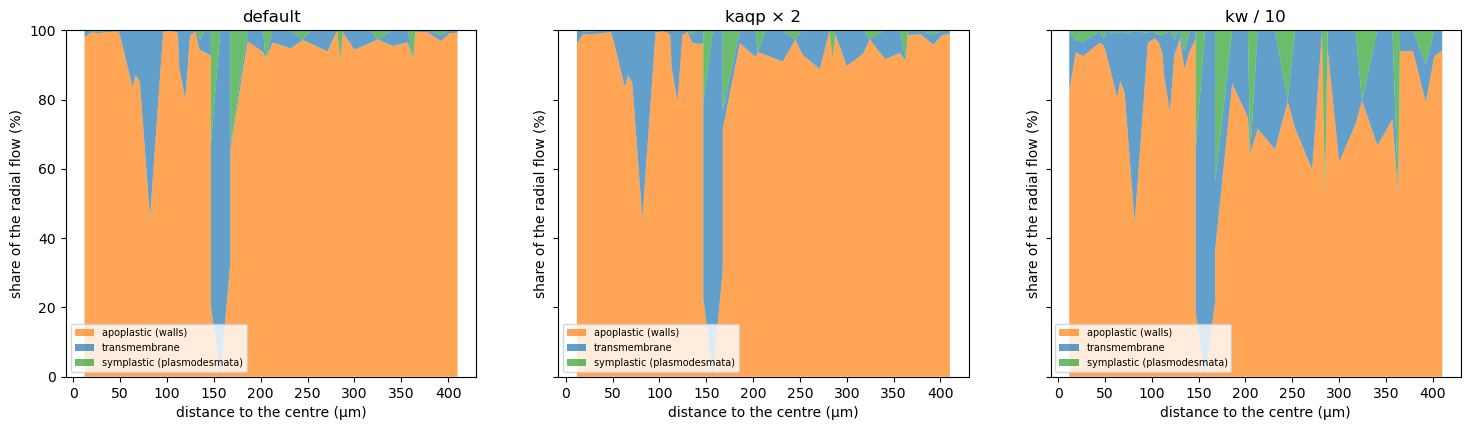

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, (name, result) in zip(axes, results.items()):
    result.draw("pathways", ax=ax)
    ax.set_title(name)

## 3. The barriers

As a root ages, its barriers mature. MECHA codes their stage by a number, `barrier`:

| code | barriers |
|---|---|
| 1 | a Casparian strip in the endodermis (young root) |
| 2 | + suberin on the endodermis, with passage cells left open |
| 3 | a fully suberized endodermis |
| 4–10 | the exodermis' strip and suberin, in various combinations |
| 11 | both the endodermis and the exodermis suberized, and the walls of the fibres (sclerenchyma) lignified |
| 0 | none: a root tip, whose xylem does not conduct yet (see tutorial 6) |

In [4]:
by_barrier = pd.DataFrame({barrier: simulate(barrier=barrier).summary for barrier in (1, 2, 3, 4, 5)}).T
by_barrier[["kr", "uptake"]]

,kr,uptake
1,0.000110,0.002772
2,0.000041,0.001025
3,0.000041,0.001025
4,0.000037,0.000942
5,0.000089,0.002240


Suberin on the endodermis (codes 2 and 3) cuts kr by almost two thirds. Codes 2 and 3 give the same value here:
GRANAP's default root has no passage cells, so "suberin with passage cells" leaves none open. An exodermal barrier
adds its own resistance.

## 4. Another anatomy

`anatomy` sets GRANAP's parameters, which generate the cross section. `{"preset": "for_dicot_root"}` is a dicot root
(like a bean). `{"cortex": {"n_layers": 3}}` keeps the monocot root but with 3 cortex layers instead of 5.

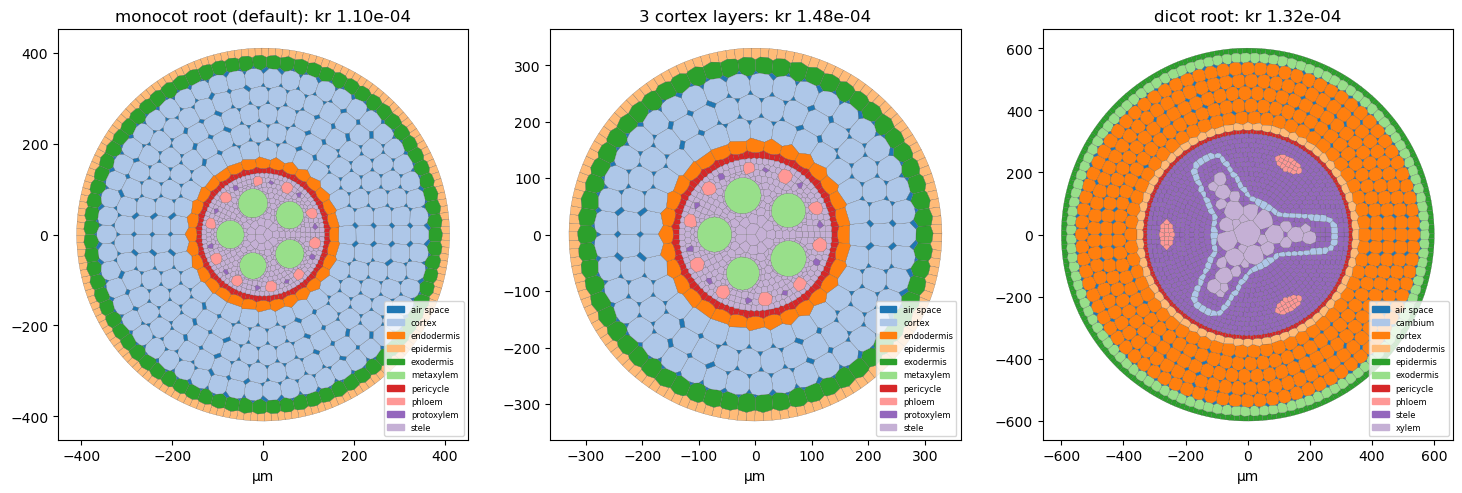

In [5]:
anatomies = {"monocot root (default)": default,
             "3 cortex layers": simulate(anatomy={"cortex": {"n_layers": 3}}),
             "dicot root": simulate(anatomy={"preset": "for_dicot_root"})}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, result) in zip(axes, anatomies.items()):
    result.draw("tissues", ax=ax)
    ax.set_title(f"{name}: kr {result.summary['kr']:.2e}")

A thinner cortex makes the path shorter: kr rises. The dicot root differs in all its tissues.

GRANAP draws the cells' sizes at random from a seed (`{"seed": 3}`), as two roots of a plant differ. kr hardly
depends on it here: about 0.04 % from one seed to another.

## Try it yourself

1. Halve the aquaporins of the endodermis only (`kaqp_endo_factor`). Compare with halving `kaqp` everywhere.
2. Which barrier code gives the lowest kr? Look at its potential map (`draw("potential")`).
3. Set the plasmodesmata conductance `kpl` to 0. Which share disappears, and how much does kr change?

**Next:** `03_combine_parameters.ipynb`.